# Feature iteration

One runnable notebook. The base table loads once at the top, each stage **adds** columns to `df`,
and an evaluation runs after every stage so the running total is visible. Re-run end to end at
any time; the final state is checkpointed to parquet at the bottom.

**How to read the results:** fold-to-fold SD is ~0.061, roughly ten times a typical feature
effect, so the *mean* alone cannot resolve a stage. Judge on the **paired per-fold delta** and its
sign pattern — a stage that improves all four folds by +0.004 is real; one that moves the mean via
a single fold is not (`report/log/010`).

**Adding a stage:** write a builder in `src/features.py`, add a two-cell block here (build +
`evaluate`), done. Nothing above needs rewriting.


In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

sys.path.insert(0, "../../src")
sys.path.insert(0, "../..")
import features as F
from modeling.evaluation import rolling_origin_cv, screening_eval, DEFAULT_PARAMS

RUN_EVAL = True      # False = build features only, skip scoring
SCREENING = True     # True = fast screen (1 fit, 150 trees, every 2nd hour); False = full 4-fold CV
CHECKPOINT = Path("../../data/processed/train_hourly_features.parquet")

INK, INK2, MUTED, GRID, BASE, SURF = "#0b0b0b","#52514e","#898781","#e1e0d9","#c3c2b7","#fcfcfb"
CAT = ["#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#008300","#4a3aa7","#e34948"]
plt.rcParams.update({"figure.facecolor":SURF,"axes.facecolor":SURF,"axes.edgecolor":BASE,
    "axes.labelcolor":INK2,"axes.titlecolor":INK,"text.color":INK,"xtick.color":MUTED,
    "ytick.color":MUTED,"grid.color":GRID,"axes.grid":True,"grid.linewidth":0.8,
    "axes.spines.top":False,"axes.spines.right":False,"font.size":11,"figure.dpi":110})
print("ready")


ready


## Setup: base table, stage ledger, evaluation helper

In [2]:
df = pd.read_parquet("../../data/processed/train_hourly.parquet")
df["year"] = df["starttime"].dt.year
TARGETS = [c for c in df.columns if c.startswith("on_")]
ID_COLS = ["run_no","split","starttime","timestamp","year"]

LEDGER = []          # one row per evaluated stage
STAGE_COLS = {}      # stage name -> columns it contributed (provenance for later ablation)
DROPPED = []         # columns removed as dead

def feature_cols():
    return [c for c in df.columns if c not in ID_COLS and c not in TARGETS and c not in DROPPED]

def add_stage(name, new_cols_df):
    """Attach a stage's columns to df and record provenance."""
    global df
    new = [c for c in new_cols_df.columns if c not in df.columns]
    df = pd.concat([df, new_cols_df[new]], axis=1)
    STAGE_COLS[name] = new
    print(f"stage '{name}': +{len(new)} cols  ->  {len(feature_cols())} features total")
    return new

def evaluate(stage_name):
    """Score the current df and append to the ledger with paired per-fold deltas."""
    if not RUN_EVAL:
        print("RUN_EVAL is False - skipping"); return None
    t0 = time.time()
    fn = screening_eval if SCREENING else rolling_origin_cv
    summary, per_fold, _ = fn(df=df, feature_cols=feature_cols(), verbose=False)
    row = {"stage": stage_name, "n_features": summary["n_features"],
           "mean": summary["mean_micro_auc"], "sd": summary["std_micro_auc"]}
    for _, r in per_fold.iterrows():
        row[int(r["validation_year"])] = r["micro_auc"]
    LEDGER.append(row)

    led = pd.DataFrame(LEDGER)
    msg = f"{stage_name:<22} mean {row['mean']:.4f}  sd {row['sd']:.4f}  ({time.time()-t0:.0f}s)"
    if len(led) > 1:
        prev = led.iloc[-2]
        years = [c for c in led.columns if isinstance(c, int)]
        deltas = {y: row[y] - prev[y] for y in years}
        n_up = sum(d > 0 for d in deltas.values())
        msg += (f"\n  vs previous: mean {row['mean']-prev['mean']:+.4f} | "
                f"per-fold " + " ".join(f"{y}:{d:+.4f}" for y, d in deltas.items()) +
                f" | {n_up}/{len(years)} folds improved")
    print(msg)
    return row

print(f"base table: {df.shape[0]:,} rows, {len(feature_cols())} features, {len(TARGETS)} targets")


base table: 490,896 rows, 54 features, 14 targets


### Stage 0 — baseline (raw features only)

In [3]:
evaluate("00_baseline")

00_baseline            mean 0.6425  sd 0.0475  (9s)


{'stage': '00_baseline',
 'n_features': 54,
 'mean': np.float64(0.6424964343735493),
 'sd': np.float64(0.047482142098544865),
 2020: np.float64(0.6902180582756507),
 2021: np.float64(0.6420137912424936),
 2022: np.float64(0.5952574536025035)}

### Stage 1 — seasonal normalisation `[R3b: storage percentile +0.537]`

Strongest single piece of EDA evidence. Built **expanding-window**: each case is ranked only
against earlier years, so CV does not see the future and the feature matches test-time
conditions.


In [4]:
add_stage("01_seasonal", F.stage_seasonal(df))

stage '01_seasonal': +4 cols  ->  58 features total


['f01_storage_pct_doy',
 'f01_wv_pct_doy',
 'f01_inflow_pct_doy',
 'f01_storage_anom']

In [5]:
evaluate("01_seasonal")

01_seasonal            mean 0.6271  sd 0.0430  (8s)
  vs previous: mean -0.0154 | per-fold 2020:-0.0215 2021:-0.0123 2022:-0.0125 | 0/3 folds improved


{'stage': '01_seasonal',
 'n_features': 58,
 'mean': np.float64(0.6270591428515379),
 'sd': np.float64(0.04302160643601121),
 2020: np.float64(0.6687115268312757),
 2021: np.float64(0.6296779461045436),
 2022: np.float64(0.5827879556187946)}

### Stage 2 — inflow regime `[R3b: trailing 365d mean +0.331]`

In [6]:
add_stage("09_inflow_regime", F.stage_inflow_regime(df))

stage '09_inflow_regime': +4 cols  ->  62 features total


['f09_inflow_trail_30d',
 'f09_inflow_trail_90d',
 'f09_inflow_trail_365d',
 'f09_inflow_30_over_365']

In [7]:
evaluate("09_inflow_regime")

09_inflow_regime       mean 0.6356  sd 0.0263  (9s)
  vs previous: mean +0.0086 | per-fold 2020:-0.0095 2021:+0.0108 2022:+0.0245 | 2/3 folds improved


{'stage': '09_inflow_regime',
 'n_features': 62,
 'mean': np.float64(0.6356392643017196),
 'sd': np.float64(0.026265978654436188),
 2020: np.float64(0.6591715809251213),
 2021: np.float64(0.6404433863264307),
 2022: np.float64(0.6073028256536069)}

### Stage 3 — case-relative price `[R3: raw −0.185 → z-scored +0.263]`

Centring flips the sign, scaling supplies the rest. Includes the day-level variants that separate
intraday shape from the weekly level.


In [8]:
add_stage("02_price_relative", F.stage_price_relative(df))

stage '02_price_relative': +8 cols  ->  70 features total

['f02_price_z_case',
 'f02_price_pct_case',
 'f02_price_log_ratio',
 'f02_price_case_std',
 'f02_price_z_day',
 'f02_price_rank_in_day',
 'f02_price_minus_case_min',
 'f02_case_max_minus_price']

In [9]:
evaluate("02_price_relative")

02_price_relative      mean 0.6720  sd 0.0194  (10s)
  vs previous: mean +0.0364 | per-fold 2020:+0.0213 2021:+0.0094 2022:+0.0785 | 3/3 folds improved


{'stage': '02_price_relative',
 'n_features': 70,
 'mean': np.float64(0.672028193142138),
 'sd': np.float64(0.019420445950001117),
 2020: np.float64(0.6804253089027862),
 2021: np.float64(0.6498221352667113),
 2022: np.float64(0.6858371352569165)}

### Stage 4 — price − water-value spread `[R2; R3: use raw, do not normalise]`

The spread is already a relative quantity; z-scoring it within the case *halved* its correlation
(+0.241 → +0.114), so it goes in raw.


In [10]:
add_stage("06_spread", F.stage_spread(df))

stage '06_spread': +11 cols  ->  81 features total


['f06_spread_sys',
 'f06_spread_Hogga',
 'f06_spread_Tokke',
 'f06_spread_Lio',
 'f06_spread_Byrte',
 'f06_spread_Vinje',
 'f06_spread_Haukeli',
 'f06_spread_Kjela',
 'f06_spread_Vesle_Kjela',
 'f06_spread_sys_positive',
 'f06_spread_hours_positive_case']

In [11]:
evaluate("06_spread")

06_spread              mean 0.7488  sd 0.0196  (11s)
  vs previous: mean +0.0767 | per-fold 2020:+0.0538 2021:+0.1213 2022:+0.0551 | 3/3 folds improved


{'stage': '06_spread',
 'n_features': 81,
 'mean': np.float64(0.7487631857587141),
 'sd': np.float64(0.019620313426053606),
 2020: np.float64(0.7342452770829683),
 2021: np.float64(0.7710846579703892),
 2022: np.float64(0.7409596222227851)}

### Stage 5 — terminal water value `[R3: −0.41 vs −0.26 for the initial value]`

The documented horizon boundary condition (start + 8 days), never previously fed to the model.
Missing for exactly one test case; the builder applies and reports a forward-fill fallback.


In [12]:
add_stage("07_terminal_wv", F.stage_terminal_wv(df))

stage '07_terminal_wv': +4 cols  ->  85 features total


['f07_terminal_wv',
 'f07_terminal_minus_initial',
 'f07_terminal_over_initial',
 'f07_price_minus_terminal_wv']

In [13]:
evaluate("07_terminal_wv")

07_terminal_wv         mean 0.7818  sd 0.0125  (13s)
  vs previous: mean +0.0331 | per-fold 2020:+0.0332 2021:+0.0192 2022:+0.0468 | 3/3 folds improved


{'stage': '07_terminal_wv',
 'n_features': 85,
 'mean': np.float64(0.7818199037982839),
 'sd': np.float64(0.012540476022877924),
 2020: np.float64(0.7674140620850618),
 2021: np.float64(0.7902945684500703),
 2022: np.float64(0.7877510808597199)}

### Stage 6 — physics: head, energy conversion, start-cost economics, penstocks 🆕

The chain *storage → `vol_head` → level → minus `outlet_line` → head → efficiency → MWh per m³*,
plus start-cost break-even hours. Static per-unit constants are useless in this row layout, so
everything here is per-plant and time-varying (or a static attribute combined with one).


In [14]:
add_stage("10_12_physics", F.stage_physics(df))

stage '10_12_physics': +72 cols  ->  157 features total


['f11_head_Hogga',
 'f11_head_frac_Hogga',
 'f11_turb_eff_Hogga',
 'f11_mwh_per_m3_Hogga',
 'f10_breakeven_hours_Hogga',
 'f10_startcost_mwh_equiv_Hogga',
 'f11_plant_energy_capacity_Hogga',
 'f12_n_penstocks_Hogga',
 'f12_units_per_penstock_Hogga',
 'f11_head_Tokke',
 'f11_head_frac_Tokke',
 'f11_turb_eff_Tokke',
 'f11_mwh_per_m3_Tokke',
 'f10_breakeven_hours_Tokke',
 'f10_startcost_mwh_equiv_Tokke',
 'f11_plant_energy_capacity_Tokke',
 'f12_n_penstocks_Tokke',
 'f12_units_per_penstock_Tokke',
 'f11_head_Lio',
 'f11_head_frac_Lio',
 'f11_turb_eff_Lio',
 'f11_mwh_per_m3_Lio',
 'f10_breakeven_hours_Lio',
 'f10_startcost_mwh_equiv_Lio',
 'f11_plant_energy_capacity_Lio',
 'f12_n_penstocks_Lio',
 'f12_units_per_penstock_Lio',
 'f11_head_Byrte',
 'f11_head_frac_Byrte',
 'f11_turb_eff_Byrte',
 'f11_mwh_per_m3_Byrte',
 'f10_breakeven_hours_Byrte',
 'f10_startcost_mwh_equiv_Byrte',
 'f11_plant_energy_capacity_Byrte',
 'f12_n_penstocks_Byrte',
 'f12_units_per_penstock_Byrte',
 'f11_head_Vinje',

In [15]:
# sanity: head must land in each plant's physical range (Tokke ~390-395 m, Kjela ~122-188 m)
print(df[[c for c in df.columns if c.startswith("f11_head_") and "frac" not in c]]
      .describe().loc[["min","max"]].round(1).T.to_string())


                        min    max
f11_head_Hogga         11.8   13.6
f11_head_Tokke        390.8  393.4
f11_head_Lio          334.8  352.7
f11_head_Byrte        264.3  299.3
f11_head_Vinje        215.5  225.4
f11_head_Haukeli      266.5  266.5
f11_head_Kjela        128.2  187.9
f11_head_Vesle_Kjela   43.7   70.2


In [16]:
evaluate("10_12_physics")

10_12_physics          mean 0.7702  sd 0.0116  (20s)
  vs previous: mean -0.0117 | per-fold 2020:-0.0054 2021:-0.0068 2022:-0.0227 | 0/3 folds improved


{'stage': '10_12_physics',
 'n_features': 157,
 'mean': np.float64(0.7701596162344032),
 'sd': np.float64(0.011617267961990682),
 2020: np.float64(0.7620026403071969),
 2021: np.float64(0.7834608327906154),
 2022: np.float64(0.7650153756053975)}

### Stage 7 — drop dead columns `[R2: two constant storage columns]`

Also catches constant columns produced by the physics stage itself: penstock counts are static
per plant, and Haukeli's entire physics block is constant because its reservoir (Vatjern) is one
of the two with no historical record.


In [17]:
DROPPED = F.drop_dead_columns(df)
print(f"{len(DROPPED)} dead (single-valued) columns removed:")
for c in DROPPED: print("   ", c)
print(f"\n{len(feature_cols())} features remain")


23 dead (single-valued) columns removed:
    storage_Hyljelihyl
    storage_Vatjern
    f12_n_penstocks_Hogga
    f12_units_per_penstock_Hogga
    f12_n_penstocks_Tokke
    f12_units_per_penstock_Tokke
    f12_n_penstocks_Lio
    f12_units_per_penstock_Lio
    f12_n_penstocks_Byrte
    f12_units_per_penstock_Byrte
    f12_n_penstocks_Vinje
    f12_units_per_penstock_Vinje
    f11_head_Haukeli
    f11_head_frac_Haukeli
    f11_turb_eff_Haukeli
    f11_mwh_per_m3_Haukeli
    f11_plant_energy_capacity_Haukeli
    f12_n_penstocks_Haukeli
    f12_units_per_penstock_Haukeli
    f12_n_penstocks_Kjela
    f12_units_per_penstock_Kjela
    f12_n_penstocks_Vesle_Kjela
    f12_units_per_penstock_Vesle_Kjela

134 features remain


In [18]:
evaluate("08_drop_dead")

08_drop_dead           mean 0.7679  sd 0.0157  (18s)
  vs previous: mean -0.0023 | per-fold 2020:-0.0096 2021:+0.0004 2022:+0.0024 | 2/3 folds improved


{'stage': '08_drop_dead',
 'n_features': 134,
 'mean': np.float64(0.7678971133588673),
 'sd': np.float64(0.0157316317028257),
 2020: np.float64(0.7524217323162493),
 2021: np.float64(0.7838730483668789),
 2022: np.float64(0.7673965593934737)}

### Stage 8 — seasonal percentile, GLOBAL variant (A/B against stage 1)

The competition withholds only test-period *targets*, so feature-side statistics may span the
whole dataset. A global statistic keeps CV valid as long as it is computed identically for train
and test rows. The expanding version is handicapped in early years, where little prior history
exists — this tests whether that was the problem, or whether the feature is simply weak.


In [19]:
add_stage("01g_seasonal_global", F.stage_seasonal_global(df))

stage '01g_seasonal_global': +3 cols  ->  137 features total


['f01g_storage_pct_doy', 'f01g_wv_pct_doy', 'f01g_inflow_pct_doy']

In [20]:
evaluate("01g_seasonal_global")

01g_seasonal_global    mean 0.7785  sd 0.0182  (19s)
  vs previous: mean +0.0106 | per-fold 2020:+0.0052 2021:+0.0073 2022:+0.0193 | 3/3 folds improved


{'stage': '01g_seasonal_global',
 'n_features': 137,
 'mean': np.float64(0.7785126108884249),
 'sd': np.float64(0.018229066369455912),
 2020: np.float64(0.7576240394690236),
 2021: np.float64(0.7912040166982653),
 2022: np.float64(0.7867097764979862)}

### Stage 9 — water budget / merit dispatch 🆕

The quantity SHOP actually resolves: limited water versus profitable hours. `merit_margin` =
hours the water can pay for minus this hour's price rank — effectively the greedy solution to the
optimizer's own problem. Hourly-varying *and* an encoded decision rule, the two properties that
won in the first pass.


In [21]:
add_stage("20_water_budget", F.stage_water_budget(df))

stage '20_water_budget': +41 cols  ->  178 features total


['f20_price_rank_desc',
 'f20_energy_avail_Hogga',
 'f20_hours_affordable_Hogga',
 'f20_merit_margin_Hogga',
 'f20_in_merit_Hogga',
 'f20_scarcity_Hogga',
 'f20_energy_avail_Tokke',
 'f20_hours_affordable_Tokke',
 'f20_merit_margin_Tokke',
 'f20_in_merit_Tokke',
 'f20_scarcity_Tokke',
 'f20_energy_avail_Lio',
 'f20_hours_affordable_Lio',
 'f20_merit_margin_Lio',
 'f20_in_merit_Lio',
 'f20_scarcity_Lio',
 'f20_energy_avail_Byrte',
 'f20_hours_affordable_Byrte',
 'f20_merit_margin_Byrte',
 'f20_in_merit_Byrte',
 'f20_scarcity_Byrte',
 'f20_energy_avail_Vinje',
 'f20_hours_affordable_Vinje',
 'f20_merit_margin_Vinje',
 'f20_in_merit_Vinje',
 'f20_scarcity_Vinje',
 'f20_energy_avail_Haukeli',
 'f20_hours_affordable_Haukeli',
 'f20_merit_margin_Haukeli',
 'f20_in_merit_Haukeli',
 'f20_scarcity_Haukeli',
 'f20_energy_avail_Kjela',
 'f20_hours_affordable_Kjela',
 'f20_merit_margin_Kjela',
 'f20_in_merit_Kjela',
 'f20_scarcity_Kjela',
 'f20_energy_avail_Vesle_Kjela',
 'f20_hours_affordable_Ves

In [22]:
evaluate("20_water_budget")

20_water_budget        mean 0.7771  sd 0.0069  (24s)
  vs previous: mean -0.0014 | per-fold 2020:+0.0157 2021:-0.0062 2022:-0.0138 | 1/3 folds improved


{'stage': '20_water_budget',
 'n_features': 178,
 'mean': np.float64(0.7770811854437536),
 'sd': np.float64(0.006874884352181518),
 2020: np.float64(0.7733228127912547),
 2021: np.float64(0.785015948630186),
 2022: np.float64(0.7729047949098204)}

### Stage 10 — spread extensions (the family that supplied 60.8% of gain)

In [23]:
add_stage("06x_spread_extended", F.stage_spread_extended(df))

stage '06x_spread_extended': +26 cols  ->  204 features total


['f06x_spread_rank_case',
 'f06x_spread_cummax_case',
 'f06x_spread_vs_case_max',
 'f06x_spread_vs_case_mean',
 'f06x_spread_fwd_12h',
 'f06x_profitable_hours_next_12h',
 'f06x_spread_fwd_24h',
 'f06x_profitable_hours_next_24h',
 'f06x_spread_fwd_48h',
 'f06x_profitable_hours_next_48h',
 'f06x_margin_Hogga',
 'f06x_spread_pos_Hogga',
 'f06x_margin_Tokke',
 'f06x_spread_pos_Tokke',
 'f06x_margin_Lio',
 'f06x_spread_pos_Lio',
 'f06x_margin_Byrte',
 'f06x_spread_pos_Byrte',
 'f06x_margin_Vinje',
 'f06x_spread_pos_Vinje',
 'f06x_margin_Haukeli',
 'f06x_spread_pos_Haukeli',
 'f06x_margin_Kjela',
 'f06x_spread_pos_Kjela',
 'f06x_margin_Vesle_Kjela',
 'f06x_spread_pos_Vesle_Kjela']

In [24]:
evaluate("06x_spread_extended")

06x_spread_extended    mean 0.7768  sd 0.0035  (27s)
  vs previous: mean -0.0003 | per-fold 2020:+0.0030 2021:-0.0045 2022:+0.0007 | 2/3 folds improved


{'stage': '06x_spread_extended',
 'n_features': 204,
 'mean': np.float64(0.776797687455379),
 'sd': np.float64(0.0034740985699001294),
 2020: np.float64(0.7762732054044992),
 2021: np.float64(0.7805042063161728),
 2022: np.float64(0.7736156506454648)}

### Stage 11 — price shape within the case (all hourly-varying)

In [25]:
add_stage("04_price_shape", F.stage_price_shape(df))

stage '04_price_shape': +8 cols  ->  212 features total


['f04_in_top_12h',
 'f04_in_top_24h',
 'f04_in_top_48h',
 'f04_in_top_72h',
 'f04_price_cummean_case',
 'f04_hours_to_case_peak',
 'f04_hours_since_case_trough',
 'f04_cum_price_share']

In [26]:
evaluate("04_price_shape")

04_price_shape         mean 0.7710  sd 0.0027  (29s)
  vs previous: mean -0.0058 | per-fold 2020:-0.0071 2021:-0.0064 2022:-0.0039 | 0/3 folds improved


{'stage': '04_price_shape',
 'n_features': 212,
 'mean': np.float64(0.7709859153463556),
 'sd': np.float64(0.002718901619128377),
 2020: np.float64(0.7691725188396756),
 2021: np.float64(0.7741121002175129),
 2022: np.float64(0.7696731269818786)}

### Stage 12 — forward/backward price windows, clipped to the horizon

In [27]:
add_stage("03_price_windows", F.stage_price_windows(df))

stage '03_price_windows': +15 cols  ->  227 features total


['f03_price_fwd_6h',
 'f03_price_minus_fwd_6h',
 'f03_price_minus_bwd_6h',
 'f03_price_fwd_12h',
 'f03_price_minus_fwd_12h',
 'f03_price_minus_bwd_12h',
 'f03_price_fwd_24h',
 'f03_price_minus_fwd_24h',
 'f03_price_minus_bwd_24h',
 'f03_price_fwd_48h',
 'f03_price_minus_fwd_48h',
 'f03_price_minus_bwd_48h',
 'f03_price_fwd_72h',
 'f03_price_minus_fwd_72h',
 'f03_price_minus_bwd_72h']

In [28]:
evaluate("03_price_windows")

03_price_windows       mean 0.7717  sd 0.0084  (32s)
  vs previous: mean +0.0007 | per-fold 2020:-0.0069 2021:+0.0044 2022:+0.0045 | 2/3 folds improved


{'stage': '03_price_windows',
 'n_features': 227,
 'mean': np.float64(0.7716538590475533),
 'sd': np.float64(0.008412030547394455),
 2020: np.float64(0.7622641126779122),
 2021: np.float64(0.7785020448584584),
 2022: np.float64(0.7741954196062896)}

### Stage 13 — water value: common factor plus deviations

In [29]:
add_stage("05_wv_structure", F.stage_wv_structure(df))

stage '05_wv_structure': +11 cols  ->  238 features total


['f05_sys_wv',
 'f05_wv_dispersion',
 'f05_wv_dev_Hogga',
 'f05_wv_dev_Tokke',
 'f05_wv_dev_Lio',
 'f05_wv_dev_Byrte',
 'f05_wv_dev_Vinje',
 'f05_wv_dev_Haukeli',
 'f05_wv_dev_Kjela',
 'f05_wv_dev_Vesle_Kjela',
 'f05_wv_rank_spread']

In [30]:
evaluate("05_wv_structure")

05_wv_structure        mean 0.7815  sd 0.0112  (36s)
  vs previous: mean +0.0099 | per-fold 2020:+0.0073 2021:+0.0133 2022:+0.0091 | 3/3 folds improved


{'stage': '05_wv_structure',
 'n_features': 238,
 'mean': np.float64(0.7815409323442871),
 'sd': np.float64(0.011222623557097149),
 2020: np.float64(0.7695577292702598),
 2021: np.float64(0.7918044669998408),
 2022: np.float64(0.7832606007627606)}

### Stage 14 — merit order crossed with the hourly economic signal

In [31]:
add_stage("15_merit_order", F.stage_merit_order(df))

stage '15_merit_order': +24 cols  ->  262 features total


['f15_units_justified_Hogga',
 'f15_cap_share_needed_Hogga',
 'f15_n_units_Hogga',
 'f15_units_justified_Tokke',
 'f15_cap_share_needed_Tokke',
 'f15_n_units_Tokke',
 'f15_units_justified_Lio',
 'f15_cap_share_needed_Lio',
 'f15_n_units_Lio',
 'f15_units_justified_Byrte',
 'f15_cap_share_needed_Byrte',
 'f15_n_units_Byrte',
 'f15_units_justified_Vinje',
 'f15_cap_share_needed_Vinje',
 'f15_n_units_Vinje',
 'f15_units_justified_Haukeli',
 'f15_cap_share_needed_Haukeli',
 'f15_n_units_Haukeli',
 'f15_units_justified_Kjela',
 'f15_cap_share_needed_Kjela',
 'f15_n_units_Kjela',
 'f15_units_justified_Vesle_Kjela',
 'f15_cap_share_needed_Vesle_Kjela',
 'f15_n_units_Vesle_Kjela']

In [32]:
evaluate("15_merit_order")

15_merit_order         mean 0.7817  sd 0.0046  (64s)
  vs previous: mean +0.0002 | per-fold 2020:+0.0069 2021:-0.0072 2022:+0.0009 | 2/3 folds improved


{'stage': '15_merit_order',
 'n_features': 262,
 'mean': np.float64(0.78174596362041),
 'sd': np.float64(0.004578400466455231),
 2020: np.float64(0.776467227511381),
 2021: np.float64(0.7846362492902118),
 2022: np.float64(0.7841344140596376)}

### Stage 15 — cascade aggregates via multi-hop graph traversal

In [33]:
add_stage("14_graph_cascade", F.stage_graph_cascade(df))

stage '14_graph_cascade': +45 cols  ->  307 features total


['f14_upstream_storage_Hogga',
 'f14_upstream_wv_Hogga',
 'f14_upstream_spread_Hogga',
 'f14_upstream_inflow_Hogga',
 'f14_n_upstream_Hogga',
 'f14_upstream_storage_Tokke',
 'f14_upstream_wv_Tokke',
 'f14_upstream_spread_Tokke',
 'f14_upstream_inflow_Tokke',
 'f14_n_upstream_Tokke',
 'f14_upstream_storage_Lio',
 'f14_upstream_wv_Lio',
 'f14_upstream_spread_Lio',
 'f14_upstream_inflow_Lio',
 'f14_n_upstream_Lio',
 'f14_upstream_storage_Byrte',
 'f14_upstream_wv_Byrte',
 'f14_upstream_spread_Byrte',
 'f14_upstream_inflow_Byrte',
 'f14_n_upstream_Byrte',
 'f14_upstream_storage_Vinje',
 'f14_upstream_wv_Vinje',
 'f14_upstream_spread_Vinje',
 'f14_upstream_inflow_Vinje',
 'f14_n_upstream_Vinje',
 'f14_upstream_storage_Haukeli',
 'f14_upstream_wv_Haukeli',
 'f14_upstream_spread_Haukeli',
 'f14_upstream_inflow_Haukeli',
 'f14_n_upstream_Haukeli',
 'f14_upstream_storage_Songa',
 'f14_upstream_wv_Songa',
 'f14_upstream_spread_Songa',
 'f14_upstream_inflow_Songa',
 'f14_n_upstream_Songa',
 'f14_

In [34]:
evaluate("14_graph_cascade")

14_graph_cascade       mean 0.7905  sd 0.0110  (79s)
  vs previous: mean +0.0088 | per-fold 2020:+0.0133 2021:+0.0172 2022:-0.0041 | 2/3 folds improved


{'stage': '14_graph_cascade',
 'n_features': 307,
 'mean': np.float64(0.7905366980810573),
 'sd': np.float64(0.010960056505504471),
 2020: np.float64(0.7897286742204508),
 2021: np.float64(0.8018784045437732),
 2022: np.float64(0.780003015478948)}

### Stage 16 — calendar and case position

In [35]:
add_stage("17_calendar", F.stage_calendar(df))

stage '17_calendar': +9 cols  ->  316 features total


['f17_hour_of_day',
 'f17_day_of_week',
 'f17_is_weekend',
 'f17_day_of_year',
 'f17_month',
 'f17_doy_sin',
 'f17_doy_cos',
 'f18_day_in_case',
 'f18_hours_remaining']

In [36]:
evaluate("17_calendar")

17_calendar            mean 0.7917  sd 0.0071  (86s)
  vs previous: mean +0.0012 | per-fold 2020:-0.0024 2021:-0.0019 2022:+0.0079 | 1/3 folds improved


{'stage': '17_calendar',
 'n_features': 316,
 'mean': np.float64(0.7917025131481665),
 'sd': np.float64(0.007138763758216459),
 2020: np.float64(0.7872995709064348),
 2021: np.float64(0.7999390917832035),
 2022: np.float64(0.7878688767548612)}

### Stage 17 — drop dead columns again (new stages add their own constants)

In [37]:
DROPPED = F.drop_dead_columns(df)
print(f"{len(DROPPED)} dead columns removed; {len(feature_cols())} features remain")


40 dead columns removed; 299 features remain


In [38]:
evaluate("08b_drop_dead")

08b_drop_dead          mean 0.7899  sd 0.0086  (82s)
  vs previous: mean -0.0018 | per-fold 2020:-0.0067 2021:-0.0023 2022:+0.0036 | 1/3 folds improved


{'stage': '08b_drop_dead',
 'n_features': 299,
 'mean': np.float64(0.789927626424277),
 'sd': np.float64(0.008619306238439536),
 2020: np.float64(0.7806269892194194),
 2021: np.float64(0.7976465034373795),
 2022: np.float64(0.7915093866160323)}

### Confirmation run

Screening is biased low and is only meant to *rank*. Re-score the final feature set under the
full rolling-origin protocol so the number is quotable and comparable to the leaderboard.


In [39]:
if RUN_EVAL:
    print("full rolling-origin CV on the final feature set:")
    s_full, pf_full, _ = rolling_origin_cv(df=df, feature_cols=feature_cols(), verbose=True)
    LEDGER.append({"stage": "FINAL (full CV)", "n_features": s_full["n_features"],
                   "mean": s_full["mean_micro_auc"], "sd": s_full["std_micro_auc"],
                   **{int(r["validation_year"]): r["micro_auc"] for _, r in pf_full.iterrows()}})


full rolling-origin CV on the final feature set:


  fold 2019: micro-AUC 0.8402  (fit 1461 cases, val 365)


  fold 2020: micro-AUC 0.7707  (fit 1826 cases, val 366)


  fold 2021: micro-AUC 0.8189  (fit 2192 cases, val 365)


  fold 2022: micro-AUC 0.8279  (fit 2557 cases, val 365)
  MEAN 0.8144  SD 0.0304  range [0.7707, 0.8402]


## Results

In [40]:
led = pd.DataFrame(LEDGER)
years = [c for c in led.columns if isinstance(c, int)]
show = led[["stage","n_features","mean","sd"] + years].copy()
show["delta_mean"] = show["mean"].diff()
show["folds_up"] = [np.nan] + [sum(led.iloc[i][y] > led.iloc[i-1][y] for y in years)
                                for i in range(1, len(led))]
show.round(4)


,stage,n_features,mean,sd,2020,2021,2022,2019,delta_mean,folds_up
0,00_baseline,54,0.6425,0.0475,0.6902,0.6420,0.5953,NaN,NaN,NaN
1,01_seasonal,58,0.6271,0.0430,0.6687,0.6297,0.5828,NaN,-0.0154,0.0
2,09_inflow_regime,62,0.6356,0.0263,0.6592,0.6404,0.6073,NaN,0.0086,2.0
3,02_price_relative,70,0.6720,0.0194,0.6804,0.6498,0.6858,NaN,0.0364,3.0
4,06_spread,81,0.7488,0.0196,0.7342,0.7711,0.7410,NaN,0.0767,3.0
5,07_terminal_wv,85,0.7818,0.0125,0.7674,0.7903,0.7878,NaN,0.0331,3.0
6,10_12_physics,157,0.7702,0.0116,0.7620,0.7835,0.7650,NaN,-0.0117,0.0
7,08_drop_dead,134,0.7679,0.0157,0.7524,0.7839,0.7674,NaN,-0.0023,2.0
8,01g_seasonal_global,137,0.7785,0.0182,0.7576,0.7912,0.7867,NaN,0.0106,3.0
9,20_water_budget,178,0.7771,0.0069,0.7733,0.7850,0.7729,NaN,-0.0014,1.0


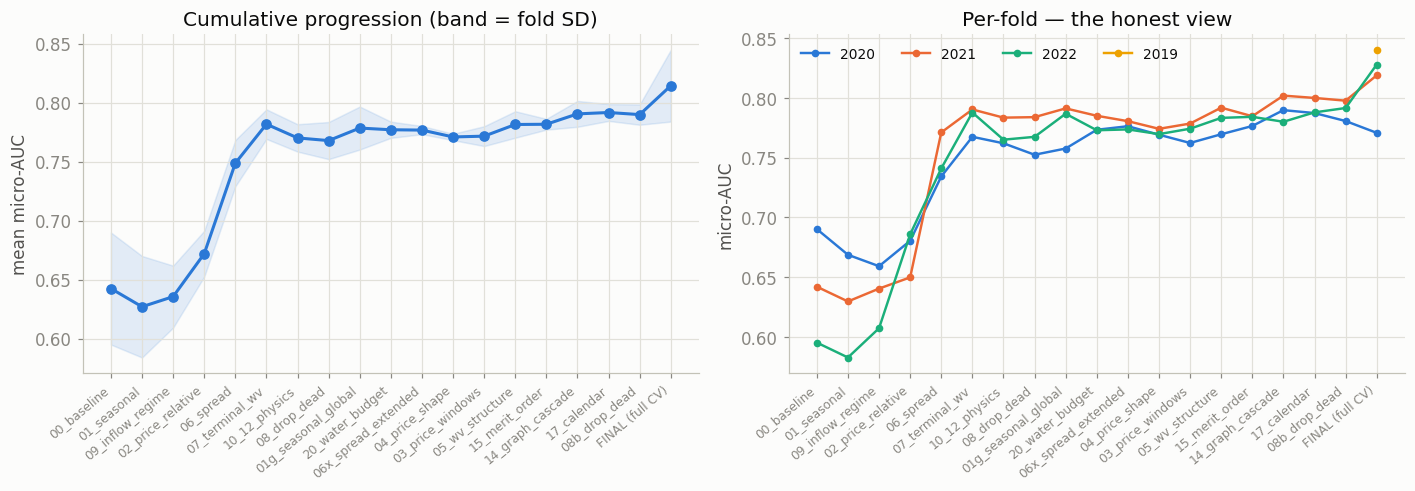

In [41]:
if len(led) > 1:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    x = np.arange(len(led))
    axes[0].plot(x, led["mean"], color=CAT[0], marker="o", lw=2)
    axes[0].fill_between(x, led["mean"]-led["sd"], led["mean"]+led["sd"], color=CAT[0], alpha=0.12)
    axes[0].set_xticks(x, led["stage"], rotation=40, ha="right", fontsize=8)
    axes[0].set_ylabel("mean micro-AUC"); axes[0].set_title("Cumulative progression (band = fold SD)")

    for i, y in enumerate(years):
        axes[1].plot(x, led[y], color=CAT[i % len(CAT)], marker="o", ms=4, lw=1.6, label=str(y))
    axes[1].set_xticks(x, led["stage"], rotation=40, ha="right", fontsize=8)
    axes[1].set_ylabel("micro-AUC"); axes[1].set_title("Per-fold — the honest view")
    axes[1].legend(frameon=False, ncol=4, fontsize=9)
    plt.tight_layout(); plt.show()


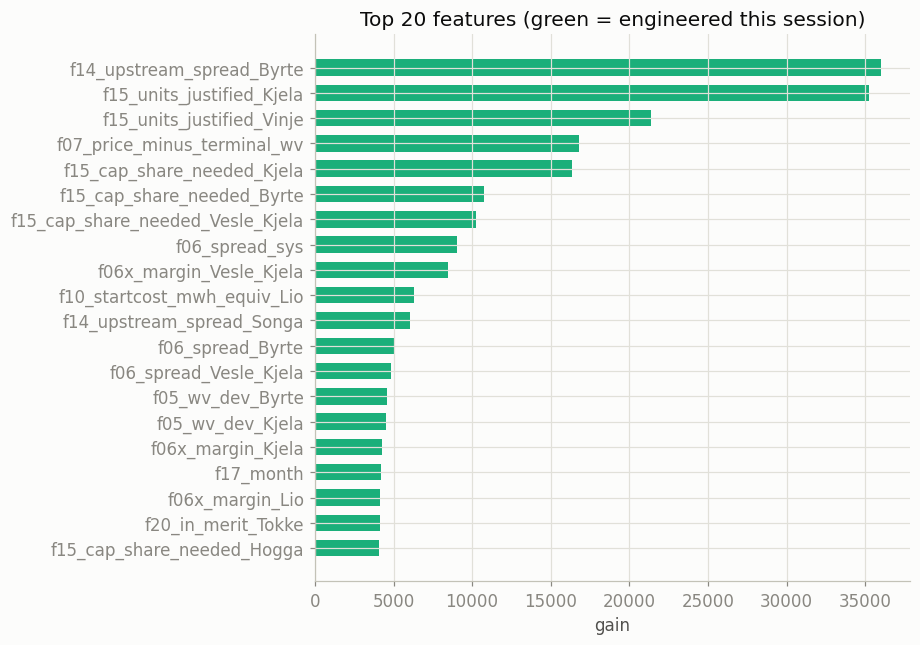

engineered features in the top 20: 20/20


In [42]:
# What is the final model actually leaning on?
from xgboost import XGBClassifier
fit = df[df["year"] < 2022]
m = XGBClassifier(**DEFAULT_PARAMS)
m.fit(fit[feature_cols()], fit[TARGETS].astype(int))
imp = pd.Series(m.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
top = imp.head(20)
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(top.index[::-1], top.values[::-1], height=0.65,
        color=[CAT[2] if i.startswith("f") else CAT[0] for i in top.index[::-1]])
ax.set_xlabel("gain"); ax.set_title("Top 20 features (green = engineered this session)")
plt.tight_layout(); plt.show()
print(f"engineered features in the top 20: {sum(i.startswith('f') for i in top.index)}/20")


## Checkpoint

In [43]:
keep = ID_COLS + feature_cols() + TARGETS
df[keep].to_parquet(CHECKPOINT, index=False)
print(f"wrote {CHECKPOINT}  ({df[keep].shape[0]:,} rows x {df[keep].shape[1]} cols)")
print("\nstage provenance:")
for k, v in STAGE_COLS.items(): print(f"  {k:<20} {len(v)} cols")


wrote ../../data/processed/train_hourly_features.parquet  (490,896 rows x 318 cols)

stage provenance:
  01_seasonal          4 cols
  09_inflow_regime     4 cols
  02_price_relative    8 cols
  06_spread            11 cols
  07_terminal_wv       4 cols
  10_12_physics        72 cols
  01g_seasonal_global  3 cols
  20_water_budget      41 cols
  06x_spread_extended  26 cols
  04_price_shape       8 cols
  03_price_windows     15 cols
  05_wv_structure      11 cols
  15_merit_order       24 cols
  14_graph_cascade     45 cols
  17_calendar          9 cols
